# Entraînement et test de différents modèles

### Préparation des données :

##### Import des librairies :

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split, cross_val_score, validation_curve, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, r2_score, mean_absolute_error)
from sklearn.pipeline import make_pipeline


##### Chargement des données d'entrainement et de test nettoyés :

In [70]:
data_train = pd.read_csv("data_train_clean.csv")
data_test = pd.read_csv("data_test_clean.csv")

data_train = data_train.drop(columns=["Unnamed: 0"])
data_test = data_test.drop(columns=["Unnamed: 0"])

In [71]:
print(data_train)

            id   Age  BodyweightKg  MeetYear  Sex  Equipment  AgeClass  \
0        27822  16.5         65.25      2016  1.0        2.0        16   
1        85202  27.0         88.50      2022  1.0        1.0        29   
2        42217  29.5         92.30      2018  0.0        1.0        29   
3       119958  27.0         52.00      2019  0.0        2.0        29   
4        37678  52.5        117.50      2025  1.0        2.0        52   
...        ...   ...           ...       ...  ...        ...       ...   
104995  119879  25.0         51.50      2012  0.0        4.0        29   
104996  103694  40.0         65.68      2015  0.0        4.0        42   
104997  131932  21.5         92.50      2017  1.0        1.0        21   
104998  146867  37.0         53.90      2024  0.0        1.0        37   
104999  121958  13.0         48.00      2007  0.0        1.0        14   

        BirthYearClass  WeightClassKg  Tested  Country  State  Federation  \
0                   16          66

##### On sépare les covariables de la variable cible dans les données d'entraînement :

In [64]:
X_train = data_train.drop(columns=["TotalKg", "id"])
Y_train = data_train["TotalKg"]
X_test = data_test.drop(columns=["id"])

##### On normalise :

In [65]:
scaler = StandardScaler()
X_train_normed = scaler.fit_transform(X_train)
X_test_normed = scaler.transform(X_test)

## Modèles :

### Régression linéaire :

##### Entraînement :

In [21]:
model = LinearRegression()
model.fit(X_train_normed, Y_train)

LinearRegression()

##### Prédictions :

In [22]:
y_pred = model.predict(X_test_normed)

submission = pd.DataFrame({
    "id": data_test["id"],
    "TotalKg": y_pred   
})
submission.to_csv("regression_submission_linear_regression.csv", index=False)

Sur kaggle, on obtient un score de 106.69270

### K plus proches voisins :

In [24]:
knn_model = KNeighborsRegressor()
knn_model.fit(X_train_normed, Y_train)

KNeighborsRegressor()

In [25]:
y_pred = knn_model.predict(X_test_normed)

submission = pd.DataFrame({
    "id": data_test["id"],
    "TotalKg": y_pred   
})
submission.to_csv("regression_submission_knn.csv", index=False)

C:\Users\slese\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\slese\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\slese\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\slese\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^

Sur kaggle, on obtient un score de 91.24507

### Arbres de décision :

`max_depth` est un hyperparamètre qui fixe la profondeur maximale de l’arbre, c’est-à-dire le nombre maximal de questions successives qu’on peut poser avant d’arriver à une prédiction. Pour le choisir, on peut utiliser une courbe de validation. Pour chaque valeur de `max_depth`, on veut savoir comment l’arbre se comporte sur des données qu’il n’a pas vues pendant son entraînement. `validation_curve` automatise cela avec une validation croisée, et renvoie les scores RMSE pour qu'on puisse les tracer. On veut évidemment obtenir la plus faible RMSE.

Il n'y a pas besoin d'utiliser `X_train_normed` pour les arbres de décision.

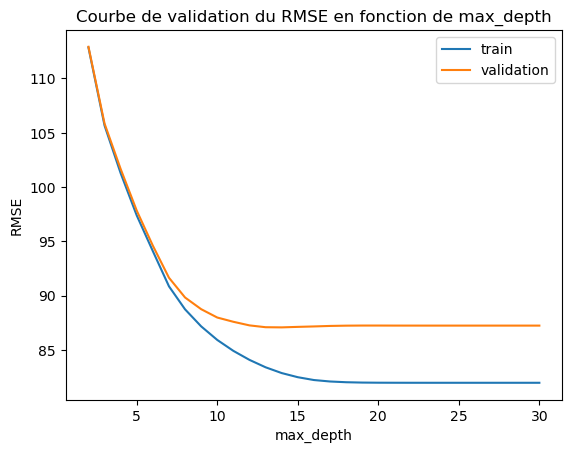

In [35]:
depths = np.arange(2, 31)

train_scores, val_scores = validation_curve(
    DecisionTreeRegressor(min_samples_leaf=50, random_state=42),
    X_train, Y_train,
    param_name="max_depth", param_range=depths,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
)

# Les scores sklearn sont négatifs (convention "plus grand = mieux"), on les remet en RMSE positif
train_rmse = -train_scores.mean(axis=1)
val_rmse = -val_scores.mean(axis=1)

plt.plot(depths, train_rmse, label="train")
plt.plot(depths, val_rmse, label="validation")
plt.title("Courbe de validation du RMSE en fonction de max_depth")
plt.xlabel("max_depth")
plt.ylabel("RMSE")
plt.legend()
plt.savefig("regression_courbe_validation.png", dpi=300)
plt.show()

In [36]:
val_rmse = -val_scores.mean(axis=1)   # RMSE positif

i_min = val_rmse.argmin()             # indice du minimum
x_min = depths[i_min]                 # max_depth optimal
y_min = val_rmse[i_min]               # RMSE minimal

print(f"Minimum : RMSE = {y_min:.2f} kg pour max_depth = {x_min}")

Minimum : RMSE = 87.06 kg pour max_depth = 14


In [37]:
model_tree = DecisionTreeRegressor(min_samples_leaf=50, max_depth=14, random_state=42) 
model_tree.fit(X_train, Y_train)

DecisionTreeRegressor(max_depth=14, min_samples_leaf=50, random_state=42)

In [38]:
y_pred = model_tree.predict(X_test)

submission = pd.DataFrame({
    "id": data_test["id"],
    "TotalKg": y_pred   
})
submission.to_csv("regression_submission_decision_tree.csv", index=False)

Sur kaggle, on obtient un score de 87.18710

### Forêt Aléatoire :

##### Recherche d'hyperparamètres :

In [40]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=20,
    max_features=0.5,     # chaque arbre ne voit qu'une partie des variables
    n_jobs=-1,
    random_state=42,
)
rf_model.fit(X_train, Y_train)

RandomForestRegressor(max_depth=15, max_features=0.5, min_samples_leaf=20,
                      n_estimators=300, n_jobs=-1, random_state=42)

In [41]:
y_pred = rf_model.predict(X_test)

submission = pd.DataFrame({
    "id": data_test["id"],
    "TotalKg": y_pred   
})
submission.to_csv("regression_submission_random_forest_naive.csv", index=False)

In [54]:
params = {
    "n_estimators": [200, 400, 600],
    "max_depth": [10, 15, 20, None],
    "min_samples_leaf": [5, 10, 20, 50],
    "max_features": [0.3, 0.5, 0.7, 1.0],   
    "max_samples": [0.5, 0.7, 0.9, None],   
}

search_rf = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=-1, random_state=42),
    params, n_iter=15, cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,          
    random_state=42,
)
search_rf.fit(X_train, Y_train)

print("Meilleurs paramètres :", search_rf.best_params_)
print(f"RMSE CV : {-search_rf.best_score_:.2f}")

Meilleurs paramètres : {'n_estimators': 200, 'min_samples_leaf': 5, 'max_samples': 0.5, 'max_features': 0.5, 'max_depth': None}
RMSE CV : 82.57


Meilleurs paramètres : {'n_estimators': 200, 'min_samples_leaf': 5, 'max_samples': 0.5, 'max_features': 0.5, 'max_depth': None}
RMSE CV : 82.57

In [55]:
best_rf = search_rf.best_estimator_
y_pred = best_rf.predict(X_test)

submission = pd.DataFrame({
    "id": data_test["id"],
    "TotalKg": y_pred   
})
submission.to_csv("regression_submission_random_forest_searchfit.csv", index=False)

Sur kaggle, on obtient un score de 84.03049 sans recherche d'hyperparamètres 

Sur kaggle, on obtient un score de 82.87571 avec recherche d'hyperparamètres

##### Permutation importance :

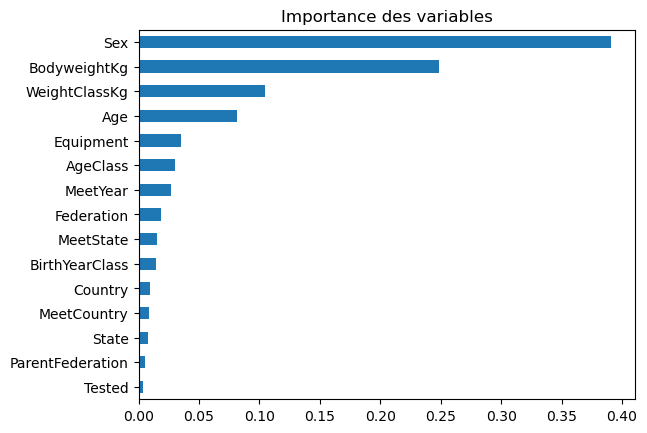

In [56]:
importances = pd.Series(best_rf.feature_importances_, index=X_train.columns)
importances.sort_values().tail(15).plot.barh()
plt.title("Importance des variables")
plt.show()

### Gradient Boosting :

##### Recherche d'hyperparamètres :

In [57]:
params = {
    "max_iter": [200, 400, 600, 1000],       
    "learning_rate": [0.02, 0.05, 0.1],
    "max_depth": [None, 4, 6, 8],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [10, 20, 50, 100],
    "l2_regularization": [0, 0.1, 1, 10],
}

search_hgb = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=42),
    params, n_iter=20, cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1, random_state=42,
)
search_hgb.fit(X_train, Y_train)

print("Meilleurs paramètres :", search_hgb.best_params_)
print(f"RMSE CV : {-search_hgb.best_score_:.2f}")

Meilleurs paramètres : {'min_samples_leaf': 100, 'max_leaf_nodes': 63, 'max_iter': 400, 'max_depth': None, 'learning_rate': 0.1, 'l2_regularization': 10}
RMSE CV : 79.29


Meilleurs paramètres : {'min_samples_leaf': 100, 'max_leaf_nodes': 63, 'max_iter': 400, 'max_depth': None, 'learning_rate': 0.1, 'l2_regularization': 10}
RMSE CV : 79.29

In [58]:
best_hgb = search_hgb.best_estimator_
y_pred = best_hgb.predict(X_test)

submission = pd.DataFrame({
    "id": data_test["id"],
    "TotalKg": y_pred   
})
submission.to_csv("regression_submission_gradient_boosting_searchfit.csv", index=False)

Sur kaggle, on obtient un score de 82.85237 sans recherche d'hyperparamètres

Sur kaggle, on obtient un score de 79.31224 avec recherche d'hyperparamètres

##### Permutation importance (afin de guider le feature engineering) :

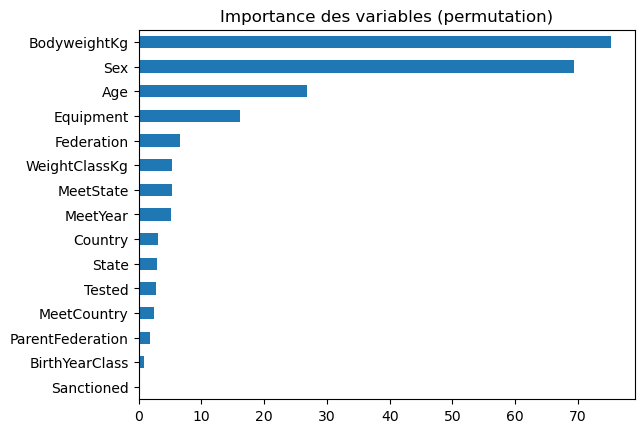

In [59]:
r = permutation_importance(best_hgb, X_train, Y_train, n_repeats=5,
                           scoring="neg_root_mean_squared_error",
                           random_state=42, n_jobs=-1)
importances = pd.Series(r.importances_mean, index=X_train.columns)
importances.sort_values().tail(15).plot.barh()
plt.title("Importance des variables (permutation)")
plt.show()

### Modèle de fondation tabulaire :

In [67]:
fond_tab_model = TabICLRegressor()
fond_tab_model.fit(X_train, Y_train)

Checkpoint 'tabicl-regressor-v2-20260212.ckpt' not cached.



tabicl-regressor-v2-20260212.ckpt:   0%|          | 0.00/114M [00:00<?, ?B/s]

C:\Users\slese\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:121: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\slese\.cache\huggingface\hub\models--jingang--TabICL. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


TabICLRegressor()

In [68]:
y_pred = fond_tab_model.predict(X_test)

submission = pd.DataFrame({
    "id": data_test["id"],
    "TotalKg": y_pred   
})
submission.to_csv("regression_submission_fond_tab.csv", index=False)


KeyboardInterrupt

